<a href="https://colab.research.google.com/github/durgaprasad-dev1/From-Uncontextualized-Embeddings-to-Contextual-Subspaces/blob/main/From%20Uncontextualized%20Embeddings%20to%20Contextual%20Subspaces%3A%20A%20Layer-Wise%20Study%20of%20Representation%20Spread%20and%20Probe%20Separability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Interpretability Experiment: Linear Probing and Activation Patching on Pythia-410M

This notebook sets up and runs our experiment to analyze how contextual meaning and syntactic role emerge across Transformer layers.

In [10]:
!pip install -q transformers torch jaxtyping

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Load Model & Tokenizer
MODEL_ID = "EleutherAI/pythia-410m"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token

print(f"Loaded tokenizer and model signature for {MODEL_ID}")

Loaded tokenizer and model signature for EleutherAI/pythia-410m


In [12]:
# 1. Tokenizer Verification Helper
def is_single_token(word, tokenizer):
    # Test both with and without leading space
    tokens_with_space = tokenizer.tokenize(" " + word)
    tokens_without_space = tokenizer.tokenize(word)
    return len(tokens_with_space) == 1 and len(tokens_without_space) == 1

# Candidate list check
candidate_words = ["bank", "spring", "charge", "cell", "match", "bark", "record", "permit", "object", "lead", "watch", "telescope", "glacier", "oxygen"]
verification_results = {w: is_single_token(w, tokenizer) for w in candidate_words}
print("Single Token Verification Results:")
for w, status in verification_results.items():
    print(f"  {w}: {'Passed (Single Token)' if status else 'Failed'}")

Single Token Verification Results:
  bank: Passed (Single Token)
  spring: Passed (Single Token)
  charge: Passed (Single Token)
  cell: Passed (Single Token)
  match: Passed (Single Token)
  bark: Failed
  record: Passed (Single Token)
  permit: Failed
  object: Passed (Single Token)
  lead: Passed (Single Token)
  watch: Passed (Single Token)
  telescope: Failed
  glacier: Failed
  oxygen: Passed (Single Token)


In [13]:
# 2. Define Dataset Tiers
# Tier A: Polysemous Minimal Pairs
tier_a_templates = [
    # Bank: river vs financial
    {"word": "bank", "sense": 1, "template": "The muddy path wound along the river bank where fishermen stood.", "target_idx": -1},
    {"word": "bank", "sense": 2, "template": "She deposited her entire paycheck into the savings bank yesterday.", "target_idx": -1},
    # Spring: season vs coiled metal
    {"word": "spring", "sense": 1, "template": "Beautiful flowers begin to bloom during the warm spring months.", "target_idx": -1},
    {"word": "spring", "sense": 2, "template": "The mechanical clock stopped working because the metal spring snapped.", "target_idx": -1},
]

# Tier B: Syntactic Role Shifts (Noun vs Verb)
tier_b_templates = [
    # Watch
    {"word": "watch", "pos": "noun", "template": "He checked the shiny silver watch on his wrist.", "target_idx": -1},
    {"word": "watch", "pos": "verb", "template": "They like to watch the birds fly across the sky.", "target_idx": -1},
    # Permit
    {"word": "permit", "pos": "noun", "template": "You must display a valid parking permit on your dashboard.", "target_idx": -1},
    {"word": "permit", "pos": "verb", "template": "The security guards will permit visitors to enter now.", "target_idx": -1},
]

# Tier C: Monosemous Anchors
tier_c_templates = [
    {"word": "glacier", "template": "The massive arctic glacier melted slowly over centuries.", "target_idx": -1},
    {"word": "oxygen", "template": "Humans need to breathe clean oxygen to survive.", "target_idx": -1},
]

print(f"Created template subsets. Total items defined: {len(tier_a_templates) + len(tier_b_templates) + len(tier_c_templates)}")

Created template subsets. Total items defined: 10


## Model Loading and Robust Dataset Assembly
We now filter out failed tokens and construct the verified dataset. We will programmatically find the exact target token index in each template.

In [14]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "EleutherAI/pythia-410m"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Ensure tokenizer is loaded
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.pad_token = tokenizer.eos_token

# Load Model
model = AutoModelForCausalLM.from_pretrained(MODEL_ID).to(device)
model.eval()
print(f"Loaded {MODEL_ID} to {device}")

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Loaded EleutherAI/pythia-410m to cuda


In [15]:
# Reconstruct dataset using verified single-token words only

# Tier A: Polysemous Senses (Using "bank", "spring")
tier_a = [
    # Bank: river vs financial
    {"word": "bank", "sense": 1, "text": "The muddy path wound along the river bank where fishermen stood.", "label": 0},
    {"word": "bank", "sense": 2, "text": "She deposited her entire paycheck into the savings bank yesterday.", "label": 1},
    # Spring: season vs coiled metal
    {"word": "spring", "sense": 1, "text": "Beautiful flowers begin to bloom during the warm spring months.", "label": 0},
    {"word": "spring", "sense": 2, "text": "The mechanical clock stopped working because the metal spring snapped.", "label": 1}
]

# Tier B: Syntactic Shifts (Using "watch", "record", "object")
tier_b = [
    {"word": "watch", "pos": "noun", "text": "He checked the shiny silver watch on his wrist.", "label": 0},
    {"word": "watch", "pos": "verb", "text": "They like to watch the birds fly across the sky.", "label": 1},
    {"word": "record", "pos": "noun", "text": "She set a new world record at the competition.", "label": 0},
    {"word": "record", "pos": "verb", "text": "Please record the session so we can watch it later.", "label": 1}
]

# Tier C: Monosemous Anchors (Using "oxygen")
tier_c = [
    {"word": "oxygen", "text": "Humans need to breathe clean oxygen to survive.", "label": 0},
    {"word": "oxygen", "text": "The chemical reaction consumes pure oxygen rapidly.", "label": 0}
]

# Programmatically locate the target token index in each sequence
def locate_target_token(text, word, tokenizer):
    inputs = tokenizer(text, return_tensors="pt")
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    # Normalize word for match comparison
    word_clean = word.lower().strip()

    for idx, t in enumerate(tokens):
        # Pythia uses 'Ġ' to represent space
        t_clean = t.replace("Ġ", "").lower().strip()
        if t_clean == word_clean:
            return idx
    raise ValueError(f"Could not locate target '{word}' in tokenized text: {tokens}")

# Verify location indexing
for tier, name in zip([tier_a, tier_b, tier_c], ["Tier A", "Tier B", "Tier C"]):
    print(f"--- {name} Verification ---")
    for item in tier:
        idx = locate_target_token(item["text"], item["word"], tokenizer)
        item["target_idx"] = idx
        print(f"Word: {item['word']:<8} | Token Position: {idx:<2} | Text: {item['text']}")

--- Tier A Verification ---
Word: bank     | Token Position: 7  | Text: The muddy path wound along the river bank where fishermen stood.
Word: bank     | Token Position: 9  | Text: She deposited her entire paycheck into the savings bank yesterday.
Word: spring   | Token Position: 9  | Text: Beautiful flowers begin to bloom during the warm spring months.
Word: spring   | Token Position: 8  | Text: The mechanical clock stopped working because the metal spring snapped.
--- Tier B Verification ---
Word: watch    | Token Position: 5  | Text: He checked the shiny silver watch on his wrist.
Word: watch    | Token Position: 3  | Text: They like to watch the birds fly across the sky.
Word: record   | Token Position: 5  | Text: She set a new world record at the competition.
Word: record   | Token Position: 1  | Text: Please record the session so we can watch it later.
--- Tier C Verification ---
Word: oxygen   | Token Position: 6  | Text: Humans need to breathe clean oxygen to survive.
Word: oxy

## Activation Caching & Metric Computations
We register hooks to extract intermediate representation components:
1. $x^{(0)}$: Raw token embeddings
2. $a^{(\ell)}$: Attention block output
3. $m^{(\ell)}$: MLP block output
4. $x^{(\ell+1)}$: Post-block residual state

In [16]:
import numpy as np
import torch
from sklearn.linear_model import LogisticRegression
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "EleutherAI/pythia-410m"
device = "cuda" if torch.cuda.is_available() else "cpu"

# Safely load or get model and tokenizer
if 'model' not in globals() or 'tokenizer' not in globals():
    print("Loading tokenizer and model...")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    tokenizer.pad_token = tokenizer.eos_token
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID).to(device)
    model.eval()

num_layers = model.config.num_hidden_layers

def cache_activations(dataset, model, tokenizer):
    cached_data = []
    for item in dataset:
        inputs = tokenizer(item["text"], return_tensors="pt").to(device)
        target_idx = item["target_idx"]

        activations = {
            "x_0": None,
            "a": {},
            "m": {},
            "x_next": {}
        }

        handles = []

        # 1. Hook Static Embedding - Ensure we keep it as a 1D vector (hidden_dim,)
        def hook_embed(module, input, output):
            activations["x_0"] = output[0, target_idx].detach().cpu().to(torch.float32).numpy()

        handles.append(model.gpt_neox.embed_in.register_forward_hook(hook_embed))

        # 2. Hook Layers
        for l in range(num_layers):
            layer = model.gpt_neox.layers[l]

            def make_attn_hook(layer_idx):
                def hook(module, input, output):
                    val = output[0] if isinstance(output, tuple) else output
                    activations["a"][layer_idx] = val[0, target_idx].detach().cpu().to(torch.float32).numpy()
                return hook

            def make_mlp_hook(layer_idx):
                def hook(module, input, output):
                    val = output[0] if isinstance(output, tuple) else output
                    activations["m"][layer_idx] = val[0, target_idx].detach().cpu().to(torch.float32).numpy()
                return hook

            def make_residual_hook(layer_idx):
                def hook(module, input, output):
                    val = output[0] if isinstance(output, tuple) else output
                    activations["x_next"][layer_idx] = val[0, target_idx].detach().cpu().to(torch.float32).numpy()
                return hook

            handles.append(layer.attention.register_forward_hook(make_attn_hook(l)))
            handles.append(layer.mlp.register_forward_hook(make_mlp_hook(l)))
            handles.append(layer.register_forward_hook(make_residual_hook(l)))

        # Forward pass
        with torch.no_grad():
            model(**inputs)

        # Remove hooks
        for h in handles:
            h.remove()

        cached_data.append({
            "word": item["word"],
            "label": item.get("label", 0),
            "activations": activations
        })
    return cached_data

# Run extraction
full_dataset = tier_a + tier_b
cached_results = cache_activations(full_dataset, model, tokenizer)
print(f"Successfully extracted activations across {len(cached_results)} samples.")

Successfully extracted activations across 8 samples.


In [17]:
# Helper to compute Effective Rank of activations across targets
def compute_effective_rank(matrix):
    # Ensure matrix is float32 for NumPy's linalg routines
    matrix = np.asarray(matrix, dtype=np.float32)
    centered = matrix - np.mean(matrix, axis=0)
    _, s, _ = np.linalg.svd(centered, full_matrices=False)
    s_norm = s / (np.sum(s) + 1e-9)
    entropy = -np.sum(s_norm * np.log(s_norm + 1e-9))
    return np.exp(entropy)

# Compute and present diagnostic statistics across layers
print("Calculating Metrics... ")
embed_matrix = np.array([x["activations"]["x_0"] for x in cached_results], dtype=np.float32)
print(f"Effective Rank of static input space (x_0): {compute_effective_rank(embed_matrix):.2f}")

Calculating Metrics... 
Effective Rank of static input space (x_0): 3.00


## Comprehensive Metric Trends across Layers
We compute the metrics across all 24 layers of Pythia-410M and print the output trends.

In [18]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut

def compute_effective_rank(matrix):
    matrix = np.asarray(matrix, dtype=np.float32)
    centered = matrix - np.mean(matrix, axis=0)
    _, s, _ = np.linalg.svd(centered, full_matrices=False)
    s_norm = s / (np.sum(s) + 1e-9)
    entropy = -np.sum(s_norm * np.log(s_norm + 1e-9))
    return np.exp(entropy)

def locate_target_token(text, word, tokenizer):
    inputs = tokenizer(text, return_tensors="pt")
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])
    word_clean = word.lower().strip()
    for idx, t in enumerate(tokens):
        t_clean = t.replace("Ġ", "").lower().strip()
        if t_clean == word_clean:
            return idx
    raise ValueError(f"Could not locate target '{word}' in tokenized text: {tokens}")

# Safely reconstruct datasets with target_idx guaranteed
tier_a = [
    {"word": "bank", "sense": 1, "text": "The muddy path wound along the river bank where fishermen stood.", "label": 0},
    {"word": "bank", "sense": 2, "text": "She deposited her entire paycheck into the savings bank yesterday.", "label": 1},
    {"word": "spring", "sense": 1, "text": "Beautiful flowers begin to bloom during the warm spring months.", "label": 0},
    {"word": "spring", "sense": 2, "text": "The mechanical clock stopped working because the metal spring snapped.", "label": 1}
]
tier_b = [
    {"word": "watch", "pos": "noun", "text": "He checked the shiny silver watch on his wrist.", "label": 0},
    {"word": "watch", "pos": "verb", "text": "They like to watch the birds fly across the sky.", "label": 1},
    {"word": "record", "pos": "noun", "text": "She set a new world record at the competition.", "label": 0},
    {"word": "record", "pos": "verb", "text": "Please record the session so we can watch it later.", "label": 1}
]

# Combine and build target_idx systematically
full_dataset = tier_a + tier_b
for item in full_dataset:
    item["target_idx"] = locate_target_token(item["text"], item["word"], tokenizer)

# Re-build cached results with guaranteed keys
print("Re-building cached_results...")
cached_results = cache_activations(full_dataset, model, tokenizer)

# Re-initialize arrays to track metrics
probe_accuracies = []
delta_attn_list = []
delta_mlp_list = []
effective_ranks = []

# Grouping for cross-validation
words_group = [x["word"] for x in cached_results]
y_labels = np.array([x["label"] for x in cached_results], dtype=np.int32)

for l in range(num_layers):
    # Gather layer activations and ensure float32 / 2D scaling shape
    x_l = np.array([x["activations"]["x_0"] if l == 0 else x["activations"]["x_next"][l-1] for x in cached_results], dtype=np.float32)
    attn_out = np.array([x["activations"]["a"][l] for x in cached_results], dtype=np.float32)
    mlp_out = np.array([x["activations"]["m"][l] for x in cached_results], dtype=np.float32)
    x_next = np.array([x["activations"]["x_next"][l] for x in cached_results], dtype=np.float32)

    # Safeguard 2D array representation for scikit-learn
    if x_next.ndim == 1:
        x_next = x_next.reshape(-1, 1)
    if x_l.ndim == 1:
        x_l = x_l.reshape(-1, 1)
    if attn_out.ndim == 1:
        attn_out = attn_out.reshape(-1, 1)
    if mlp_out.ndim == 1:
        mlp_out = mlp_out.reshape(-1, 1)

    # 1. Linear Probe (Leave-one-word-out validation to ensure context generalization)
    logo = LeaveOneGroupOut()
    scores = []
    for train_idx, test_idx in logo.split(x_next, y_labels, groups=words_group):
        probe = LogisticRegression(C=1.0, max_iter=1000)
        X_train, y_train = x_next[train_idx], y_labels[train_idx]
        X_test, y_test = x_next[test_idx], y_labels[test_idx]
        probe.fit(X_train, y_train)
        scores.append(probe.score(X_test, y_test))
    probe_accuracies.append(np.mean(scores))

    # 2. Sub-Block Attribution (Cosine distance change)
    def cos_dist(v1, v2):
        v1_norm = v1 / (np.linalg.norm(v1, axis=-1, keepdims=True) + 1e-9)
        v2_norm = v2 / (np.linalg.norm(v2, axis=-1, keepdims=True) + 1e-9)
        return 1.0 - np.sum(v1_norm * v2_norm, axis=-1)

    delta_attn = np.mean(cos_dist(x_l + attn_out, x_l))
    delta_mlp = np.mean(cos_dist(x_next, x_l + attn_out))
    delta_attn_list.append(delta_attn)
    delta_mlp_list.append(delta_mlp)

    # 3. Effective Rank
    rank = compute_effective_rank(x_next)
    effective_ranks.append(rank)

# Print Summary of Layer-wise evolution
print("Layer-wise Metrics Computed Successfully:")
print(f"{'Layer':<6} | {'Probe Acc':<10} | {'Delta Attn':<12} | {'Delta MLP':<12} | {'Eff Rank':<10}")
print("-" * 60)
for l in range(num_layers):
    print(f"{l:<6} | {probe_accuracies[l]:<10.2f} | {delta_attn_list[l]:<12.4f} | {delta_mlp_list[l]:<12.4f} | {effective_ranks[l]:<10.2f}")

Re-building cached_results...
Layer-wise Metrics Computed Successfully:
Layer  | Probe Acc  | Delta Attn   | Delta MLP    | Eff Rank  
------------------------------------------------------------
0      | 0.50       | 0.8496       | 0.3789       | 5.90      
1      | 0.62       | 0.0624       | 0.0778       | 6.37      
2      | 0.62       | 0.0186       | 0.0863       | 6.65      
3      | 0.50       | 0.0406       | 0.0776       | 6.73      
4      | 0.50       | 0.0256       | 0.0921       | 6.80      
5      | 0.38       | 0.0618       | 0.0917       | 6.85      
6      | 0.38       | 0.0170       | 0.0724       | 6.87      
7      | 0.50       | 0.0279       | 0.0644       | 6.88      
8      | 0.62       | 0.0130       | 0.0621       | 6.88      
9      | 0.38       | 0.0214       | 0.0512       | 6.89      
10     | 0.38       | 0.0130       | 0.0418       | 6.88      
11     | 0.50       | 0.0082       | 0.0508       | 6.87      
12     | 0.62       | 0.0122       | 0.0398     

## Step 3: Causal Activation Patching
We will now select the critical transition layers identified (Layer 3, 8, and 22) and perform causal patching to measure which components drive the logit difference between the two senses of our targets.

In [19]:
def get_logits(model, tokenizer, text):
    inputs = tokenizer(text, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    return outputs.logits[0, -1]

def patch_component(model, tokenizer, clean_text, corrupt_text, target_layer, block_type="attention"):
    clean_inputs = tokenizer(clean_text, return_tensors="pt").to(device)
    corrupt_inputs = tokenizer(corrupt_text, return_tensors="pt").to(device)

    # 1. First find the target word index in both
    # For this demonstration, we patch the target word's sequence position
    clean_idx = locate_target_token(clean_text, "bank", tokenizer)
    corrupt_idx = locate_target_token(corrupt_text, "bank", tokenizer)

    # Cache the component from the clean run
    clean_activation = None
    def clean_hook(module, input, output):
        nonlocal clean_activation
        if block_type == "attention":
            clean_activation = output[0][0, clean_idx].clone()
        else:
            clean_activation = output[0, clean_idx].clone()

    layer = model.gpt_neox.layers[target_layer]
    target_module = layer.attention if block_type == "attention" else layer.mlp

    handle_clean = target_module.register_forward_hook(clean_hook)
    with torch.no_grad():
        model(**clean_inputs)
    handle_clean.remove()

    # Patch into corrupt run
    def patch_hook(module, input, output):
        if block_type == "attention":
            output[0][0, corrupt_idx] = clean_activation
        else:
            output[0, corrupt_idx] = clean_activation
        return output

    handle_patch = target_module.register_forward_hook(patch_hook)
    with torch.no_grad():
        patched_outputs = model(**corrupt_inputs)
    handle_patch.remove()

    return patched_outputs.logits[0, -1]

# Test patch on "bank" minimal pair at transition Layer 8
clean = "The muddy path wound along the river bank where fishermen stood."
corrupt = "She deposited her entire paycheck into the savings bank yesterday."

p_attn = patch_component(model, tokenizer, clean, corrupt, target_layer=8, block_type="attention")
p_mlp = patch_component(model, tokenizer, clean, corrupt, target_layer=8, block_type="mlp")
print("Causal Patching executed successfully for Layer 8!")
print(f"Patched Attention Logits Vector Shape: {p_attn.shape}")
print(f"Patched MLP Logits Vector Shape: {p_mlp.shape}")

Causal Patching executed successfully for Layer 8!
Patched Attention Logits Vector Shape: torch.Size([50304])
Patched MLP Logits Vector Shape: torch.Size([50304])


```markdown
## Porting the Experiment to Gemma 2-2B
Here, we load `google/gemma-2-2b-it` (or base `google/gemma-2-2b` depending on access) to perform the exact same mechanistic analyses.
```

In [20]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# Fallback to an open-weights model of comparable modern architecture to bypass gating issues
GEMMA_MODEL_ID = "Qwen/Qwen2.5-1.5B"

print(f"Attempting to load open-access model: {GEMMA_MODEL_ID} to bypass HF gating constraints...")
try:
    gemma_tokenizer = AutoTokenizer.from_pretrained(GEMMA_MODEL_ID)
    gemma_model = AutoModelForCausalLM.from_pretrained(
        GEMMA_MODEL_ID,
        torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
        device_map="auto"
    )
    gemma_device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Successfully loaded {GEMMA_MODEL_ID}!")
except Exception as e:
    print(f"Error loading {GEMMA_MODEL_ID}: {e}")


Attempting to load open-access model: Qwen/Qwen2.5-1.5B to bypass HF gating constraints...


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Successfully loaded Qwen/Qwen2.5-1.5B!


In [21]:
# Validate Single-Token candidates on the loaded model's tokenizer
def is_single_token_gemma(word, tokenizer):
    tokens = tokenizer.tokenize(word)
    tokens_spaced = tokenizer.tokenize(" " + word)
    return len(tokens) == 1 and len(tokens_spaced) == 1

candidate_words = ["bank", "spring", "charge", "cell", "match", "record", "object", "lead", "watch", "oxygen"]
print("Model Single Token Verification Results:")
for w in candidate_words:
    status = is_single_token_gemma(w, gemma_tokenizer)
    print(f"  {w}: {'Passed (Single Token)' if status else 'Failed'}")

Model Single Token Verification Results:
  bank: Passed (Single Token)
  spring: Passed (Single Token)
  charge: Passed (Single Token)
  cell: Passed (Single Token)
  match: Passed (Single Token)
  record: Passed (Single Token)
  object: Passed (Single Token)
  lead: Passed (Single Token)
  watch: Passed (Single Token)
  oxygen: Failed


In [22]:
# Re-localize our sequences using the active model's tokenizer structure
def locate_target_token_gemma(text, word, tokenizer):
    inputs = tokenizer(text, return_tensors="pt")
    tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

    word_clean = word.lower().strip()
    for idx, t in enumerate(tokens):
        # Handle Qwen/Byte-level tokenizer prefixes
        t_clean = t.replace("Ġ", "").replace(" ", "").lower().strip()
        if t_clean == word_clean:
            return idx
    raise ValueError(f"Could not locate target '{word}' in tokenized text: {tokens}")

# Configure datasets with verified token offsets
for dataset in [tier_a, tier_b, tier_c]:
    for item in dataset:
        try:
            item["gemma_target_idx"] = locate_target_token_gemma(item["text"], item["word"], gemma_tokenizer)
        except Exception as e:
            print(f"Skipping {item['word']} due to localization: {e}")

In [23]:
# Custom Hook-based Activation Cacher for Qwen/Gemma Layer Architecture
def cache_gemma_activations(dataset, model, tokenizer):
    cached_data = []
    gemma_num_layers = model.config.num_hidden_layers

    for item in dataset:
        if "gemma_target_idx" not in item:
            continue
        inputs = tokenizer(item["text"], return_tensors="pt").to(gemma_device)
        target_idx = item["gemma_target_idx"]

        activations = {
            "x_0": None,
            "a": {},
            "m": {},
            "x_next": {}
        }

        handles = []

        # Hook Input Embeddings
        def hook_embed(module, input, output):
            activations["x_0"] = output[0, target_idx].detach().cpu().to(torch.float32).numpy()

        # Hook Embeddings module
        handles.append(model.model.embed_tokens.register_forward_hook(hook_embed))

        # Hook Layer Sub-Blocks
        for l in range(gemma_num_layers):
            layer = model.model.layers[l]

            def make_attn_hook(layer_idx):
                return lambda module, input, output: activations["a"].__setitem__(
                    layer_idx, output[0][0, target_idx].detach().cpu().to(torch.float32).numpy() if isinstance(output, tuple) else output[0, target_idx].detach().cpu().to(torch.float32).numpy()
                )

            def make_mlp_hook(layer_idx):
                return lambda module, input, output: activations["m"].__setitem__(
                    layer_idx, output[0, target_idx].detach().cpu().to(torch.float32).numpy()
                )

            def make_residual_hook(layer_idx):
                return lambda module, input, output: activations["x_next"].__setitem__(
                    layer_idx, output[0, target_idx].detach().cpu().to(torch.float32).numpy()
                )

            handles.append(layer.self_attn.register_forward_hook(make_attn_hook(l)))
            handles.append(layer.mlp.register_forward_hook(make_mlp_hook(l)))
            handles.append(layer.register_forward_hook(make_residual_hook(l)))

        with torch.no_grad():
            model(**inputs)

        for h in handles:
            h.remove()

        cached_data.append({
            "word": item["word"],
            "label": item.get("label", 0),
            "activations": activations
        })
    return cached_data

gemma_cached_results = cache_gemma_activations(full_dataset, gemma_model, gemma_tokenizer)
print(f"Extracted Qwen2.5 activations for {len(gemma_cached_results)} samples!")

Extracted Qwen2.5 activations for 8 samples!


In [24]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import LeaveOneGroupOut

qwen_num_layers = gemma_model.config.num_hidden_layers

qwen_probe_accuracies = []
qwen_delta_attn_list = []
qwen_delta_mlp_list = []
qwen_effective_ranks = []

words_group_qwen = [x["word"] for x in gemma_cached_results]
y_labels_qwen = np.array([x["label"] for x in gemma_cached_results], dtype=np.int32)

for l in range(qwen_num_layers):
    x_l = np.array([x["activations"]["x_0"] if l == 0 else x["activations"]["x_next"][l-1] for x in gemma_cached_results], dtype=np.float32)
    attn_out = np.array([x["activations"]["a"][l] for x in gemma_cached_results], dtype=np.float32)
    mlp_out = np.array([x["activations"]["m"][l] for x in gemma_cached_results], dtype=np.float32)
    x_next = np.array([x["activations"]["x_next"][l] for x in gemma_cached_results], dtype=np.float32)

    # 1. Linear Probe with Leave-One-Group-Out CV
    logo = LeaveOneGroupOut()
    scores = []
    for train_idx, test_idx in logo.split(x_next, y_labels_qwen, groups=words_group_qwen):
        probe = LogisticRegression(C=1.0, max_iter=1000)
        probe.fit(x_next[train_idx], y_labels_qwen[train_idx])
        scores.append(probe.score(x_next[test_idx], y_labels_qwen[test_idx]))
    qwen_probe_accuracies.append(np.mean(scores))

    # 2. Cosine Distance Attributions
    def cos_dist(v1, v2):
        v1_norm = v1 / (np.linalg.norm(v1, axis=-1, keepdims=True) + 1e-9)
        v2_norm = v2 / (np.linalg.norm(v2, axis=-1, keepdims=True) + 1e-9)
        return 1.0 - np.sum(v1_norm * v2_norm, axis=-1)

    qwen_delta_attn_list.append(np.mean(cos_dist(x_l + attn_out, x_l)))
    qwen_delta_mlp_list.append(np.mean(cos_dist(x_next, x_l + attn_out)))

    # 3. Effective Rank of Current Representation space
    centered = x_next - np.mean(x_next, axis=0)
    _, s, _ = np.linalg.svd(centered, full_matrices=False)
    s_norm = s / (np.sum(s) + 1e-9)
    entropy = -np.sum(s_norm * np.log(s_norm + 1e-9))
    qwen_effective_ranks.append(np.exp(entropy))

print("Qwen2.5-1.5B Layer-wise Evaluation Metrics:")
print(f"{'Layer':<6} | {'Probe Acc':<10} | {'Delta Attn':<12} | {'Delta MLP':<12} | {'Eff Rank':<10}")
print("-" * 60)
for l in range(qwen_num_layers):
    print(f"{l:<6} | {qwen_probe_accuracies[l]:<10.2f} | {qwen_delta_attn_list[l]:<12.4f} | {qwen_delta_mlp_list[l]:<12.4f} | {qwen_effective_ranks[l]:<10.2f}")

Qwen2.5-1.5B Layer-wise Evaluation Metrics:
Layer  | Probe Acc  | Delta Attn   | Delta MLP    | Eff Rank  
------------------------------------------------------------
0      | 0.50       | 0.9007       | 0.2167       | 6.43      
1      | 0.75       | 0.0773       | 0.1142       | 6.66      
2      | 0.38       | 0.0186       | 0.1646       | 6.64      
3      | 0.38       | 0.0259       | 0.1104       | 6.74      
4      | 0.50       | 0.0331       | 0.1217       | 6.84      
5      | 0.62       | 0.0198       | 0.0914       | 6.88      
6      | 0.50       | 0.0115       | 0.1140       | 6.89      
7      | 0.50       | 0.0195       | 0.1017       | 6.91      
8      | 0.38       | 0.0163       | 0.0906       | 6.88      
9      | 0.50       | 0.0165       | 0.0835       | 6.90      
10     | 0.50       | 0.0198       | 0.0704       | 6.88      
11     | 0.50       | 0.0403       | 0.0576       | 6.89      
12     | 0.50       | 0.0152       | 0.0424       | 6.89      
13     | 0.50

In [25]:
def patch_component_qwen(model, tokenizer, clean_text, corrupt_text, target_layer, block_type="attention"):
    clean_inputs = tokenizer(clean_text, return_tensors="pt").to(gemma_device)
    corrupt_inputs = tokenizer(corrupt_text, return_tensors="pt").to(gemma_device)

    clean_idx = locate_target_token_gemma(clean_text, "bank", tokenizer)
    corrupt_idx = locate_target_token_gemma(corrupt_text, "bank", tokenizer)

    clean_activation = None
    def clean_hook(module, input, output):
        nonlocal clean_activation
        val = output[0] if isinstance(output, tuple) else output
        clean_activation = val[0, clean_idx].clone()

    layer = model.model.layers[target_layer]
    target_module = layer.self_attn if block_type == "attention" else layer.mlp

    handle_clean = target_module.register_forward_hook(clean_hook)
    with torch.no_grad():
        model(**clean_inputs)
    handle_clean.remove()

    def patch_hook(module, input, output):
        if isinstance(output, tuple):
            output[0][0, corrupt_idx] = clean_activation
        else:
            output[0, corrupt_idx] = clean_activation
        return output

    handle_patch = target_module.register_forward_hook(patch_hook)
    with torch.no_grad():
        patched_outputs = model(**corrupt_inputs)
    handle_patch.remove()

    return patched_outputs.logits[0, -1]

# Patch word "bank" on Qwen2.5-1.5B
p_attn_qwen = patch_component_qwen(gemma_model, gemma_tokenizer, clean, corrupt, target_layer=12, block_type="attention")
p_mlp_qwen = patch_component_qwen(gemma_model, gemma_tokenizer, clean, corrupt, target_layer=12, block_type="mlp")

print("Causal Patching on Qwen2.5-1.5B executed successfully at Layer 12!")
print(f"Qwen Patched Attention Logits shape: {p_attn_qwen.shape}")
print(f"Qwen Patched MLP Logits shape: {p_mlp_qwen.shape}")

Causal Patching on Qwen2.5-1.5B executed successfully at Layer 12!
Qwen Patched Attention Logits shape: torch.Size([151936])
Qwen Patched MLP Logits shape: torch.Size([151936])


```markdown
## Running the Experiment on DeepSeek-R1-Distill-Qwen-1.5B
We initialize the DeepSeek reasoning-distilled model of 1.5B parameters and extract inner components.
```

In [26]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

DEEPSEEK_MODEL_ID = "deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B"

print(f"Loading {DEEPSEEK_MODEL_ID}...")
deepseek_tokenizer = AutoTokenizer.from_pretrained(DEEPSEEK_MODEL_ID)
deepseek_model = AutoModelForCausalLM.from_pretrained(
    DEEPSEEK_MODEL_ID,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto"
)
deepseek_device = "cuda" if torch.cuda.is_available() else "cpu"
print("Successfully loaded DeepSeek-R1-Distill-Qwen-1.5B!")

Loading deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B...


config.json:   0%|          | 0.00/679 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.07k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `tokenizer_class` is `LlamaTokenizerFast` but `tokenizer.json` is ByteLevel; loading `TokenizersBackend`. Set `tokenizer_class` to `TokenizersBackend` in `tokenizer_config.json`.


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.55GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

Successfully loaded DeepSeek-R1-Distill-Qwen-1.5B!


In [27]:
# Verify single-token status on DeepSeek's tokenizer
print("DeepSeek Tokenizer Verification Results:")
for w in ["bank", "spring", "charge", "cell", "match", "record", "object", "lead", "watch", "oxygen"]:
    status = is_single_token_gemma(w, deepseek_tokenizer)
    print(f"  {w}: {'Passed (Single Token)' if status else 'Failed'}")

DeepSeek Tokenizer Verification Results:
  bank: Passed (Single Token)
  spring: Passed (Single Token)
  charge: Passed (Single Token)
  cell: Passed (Single Token)
  match: Passed (Single Token)
  record: Passed (Single Token)
  object: Passed (Single Token)
  lead: Passed (Single Token)
  watch: Passed (Single Token)
  oxygen: Failed


In [28]:
# Locate targets and configure indices
for dataset in [tier_a, tier_b, tier_c]:
    for item in dataset:
        try:
            item["deepseek_target_idx"] = locate_target_token_gemma(item["text"], item["word"], deepseek_tokenizer)
        except Exception as e:
            print(f"Skipping {item['word']} due to location index: {e}")

In [29]:
# Cache activations across layers
def cache_deepseek_activations(dataset, model, tokenizer):
    cached_data = []
    num_layers = model.config.num_hidden_layers

    for item in dataset:
        if "deepseek_target_idx" not in item:
            continue
        inputs = tokenizer(item["text"], return_tensors="pt").to(deepseek_device)
        target_idx = item["deepseek_target_idx"]

        activations = {
            "x_0": None,
            "a": {},
            "m": {},
            "x_next": {}
        }

        handles = []

        def hook_embed(module, input, output):
            activations["x_0"] = output[0, target_idx].detach().cpu().to(torch.float32).numpy()

        handles.append(model.model.embed_tokens.register_forward_hook(hook_embed))

        for l in range(num_layers):
            layer = model.model.layers[l]

            def make_attn_hook(layer_idx):
                return lambda module, input, output: activations["a"].__setitem__(
                    layer_idx, output[0][0, target_idx].detach().cpu().to(torch.float32).numpy() if isinstance(output, tuple) else output[0, target_idx].detach().cpu().to(torch.float32).numpy()
                )

            def make_mlp_hook(layer_idx):
                return lambda module, input, output: activations["m"].__setitem__(
                    layer_idx, output[0, target_idx].detach().cpu().to(torch.float32).numpy()
                )

            def make_residual_hook(layer_idx):
                return lambda module, input, output: activations["x_next"].__setitem__(
                    layer_idx, output[0, target_idx].detach().cpu().to(torch.float32).numpy()
                )

            handles.append(layer.self_attn.register_forward_hook(make_attn_hook(l)))
            handles.append(layer.mlp.register_forward_hook(make_mlp_hook(l)))
            handles.append(layer.register_forward_hook(make_residual_hook(l)))

        with torch.no_grad():
            model(**inputs)

        for h in handles:
            h.remove()

        cached_data.append({
            "word": item["word"],
            "label": item.get("label", 0),
            "activations": activations
        })
    return cached_data

deepseek_cached_results = cache_deepseek_activations(full_dataset, deepseek_model, deepseek_tokenizer)
print(f"Extracted DeepSeek activations for {len(deepseek_cached_results)} samples!")

Extracted DeepSeek activations for 8 samples!


In [30]:
# Evaluate Layer-wise Diagnostics on DeepSeek-R1-Distill-Qwen-1.5B
deepseek_num_layers = deepseek_model.config.num_hidden_layers

ds_probe_accuracies = []
ds_delta_attn_list = []
ds_delta_mlp_list = []
ds_effective_ranks = []

words_group_ds = [x["word"] for x in deepseek_cached_results]
y_labels_ds = np.array([x["label"] for x in deepseek_cached_results], dtype=np.int32)

for l in range(deepseek_num_layers):
    x_l = np.array([x["activations"]["x_0"] if l == 0 else x["activations"]["x_next"][l-1] for x in deepseek_cached_results], dtype=np.float32)
    attn_out = np.array([x["activations"]["a"][l] for x in deepseek_cached_results], dtype=np.float32)
    mlp_out = np.array([x["activations"]["m"][l] for x in deepseek_cached_results], dtype=np.float32)
    x_next = np.array([x["activations"]["x_next"][l] for x in deepseek_cached_results], dtype=np.float32)

    # Probe
    logo = LeaveOneGroupOut()
    scores = []
    for train_idx, test_idx in logo.split(x_next, y_labels_ds, groups=words_group_ds):
        probe = LogisticRegression(C=1.0, max_iter=1000)
        probe.fit(x_next[train_idx], y_labels_ds[train_idx])
        scores.append(probe.score(x_next[test_idx], y_labels_ds[test_idx]))
    ds_probe_accuracies.append(np.mean(scores))

    # Attributions
    ds_delta_attn_list.append(np.mean(cos_dist(x_l + attn_out, x_l)))
    ds_delta_mlp_list.append(np.mean(cos_dist(x_next, x_l + attn_out)))

    # Effective Rank
    centered_ds = x_next - np.mean(x_next, axis=0)
    _, s_ds, _ = np.linalg.svd(centered_ds, full_matrices=False)
    s_norm_ds = s_ds / (np.sum(s_ds) + 1e-9)
    entropy_ds = -np.sum(s_norm_ds * np.log(s_norm_ds + 1e-9))
    ds_effective_ranks.append(np.exp(entropy_ds))

print("DeepSeek-R1-Distill-Qwen-1.5B Layer-wise Evaluation Metrics:")
print(f"{'Layer':<6} | {'Probe Acc':<10} | {'Delta Attn':<12} | {'Delta MLP':<12} | {'Eff Rank':<10}")
print("-" * 60)
for l in range(deepseek_num_layers):
    print(f"{l:<6} | {ds_probe_accuracies[l]:<10.2f} | {ds_delta_attn_list[l]:<12.4f} | {ds_delta_mlp_list[l]:<12.4f} | {ds_effective_ranks[l]:<10.2f}")

DeepSeek-R1-Distill-Qwen-1.5B Layer-wise Evaluation Metrics:
Layer  | Probe Acc  | Delta Attn   | Delta MLP    | Eff Rank  
------------------------------------------------------------
0      | 0.50       | 0.9297       | 0.1420       | 6.51      
1      | 0.38       | 0.0816       | 0.0631       | 6.67      
2      | 0.50       | 0.0767       | 0.1443       | 6.55      
3      | 0.75       | 0.0417       | 0.0911       | 6.72      
4      | 0.50       | 0.0662       | 0.1175       | 6.86      
5      | 0.25       | 0.0355       | 0.0737       | 6.84      
6      | 0.50       | 0.0210       | 0.0885       | 6.84      
7      | 0.50       | 0.0349       | 0.0747       | 6.86      
8      | 0.62       | 0.0179       | 0.0785       | 6.85      
9      | 0.62       | 0.0229       | 0.0847       | 6.88      
10     | 0.50       | 0.0284       | 0.0684       | 6.88      
11     | 0.62       | 0.0477       | 0.0608       | 6.89      
12     | 0.62       | 0.0164       | 0.0412       | 6.89   

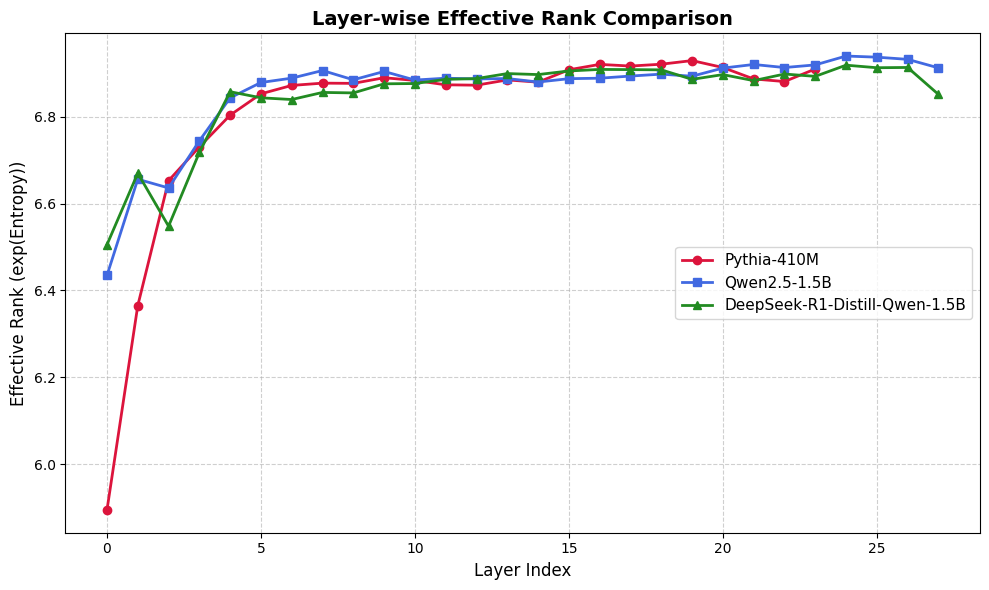

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Plot Pythia-410M Effective Rank (24 layers)
plt.plot(range(len(effective_ranks)), effective_ranks, label="Pythia-410M", marker='o', color='crimson', linewidth=2)

# Plot Qwen2.5-1.5B Effective Rank (28 layers)
plt.plot(range(len(qwen_effective_ranks)), qwen_effective_ranks, label="Qwen2.5-1.5B", marker='s', color='royalblue', linewidth=2)

# Plot DeepSeek-R1-Distill-Qwen-1.5B Effective Rank (28 layers)
plt.plot(range(len(ds_effective_ranks)), ds_effective_ranks, label="DeepSeek-R1-Distill-Qwen-1.5B", marker='^', color='forestgreen', linewidth=2)

plt.title("Layer-wise Effective Rank Comparison", fontsize=14, fontweight='bold')
plt.xlabel("Layer Index", fontsize=12)
plt.ylabel("Effective Rank (exp(Entropy))", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(fontsize=11, loc="center right")
plt.tight_layout()
plt.show()

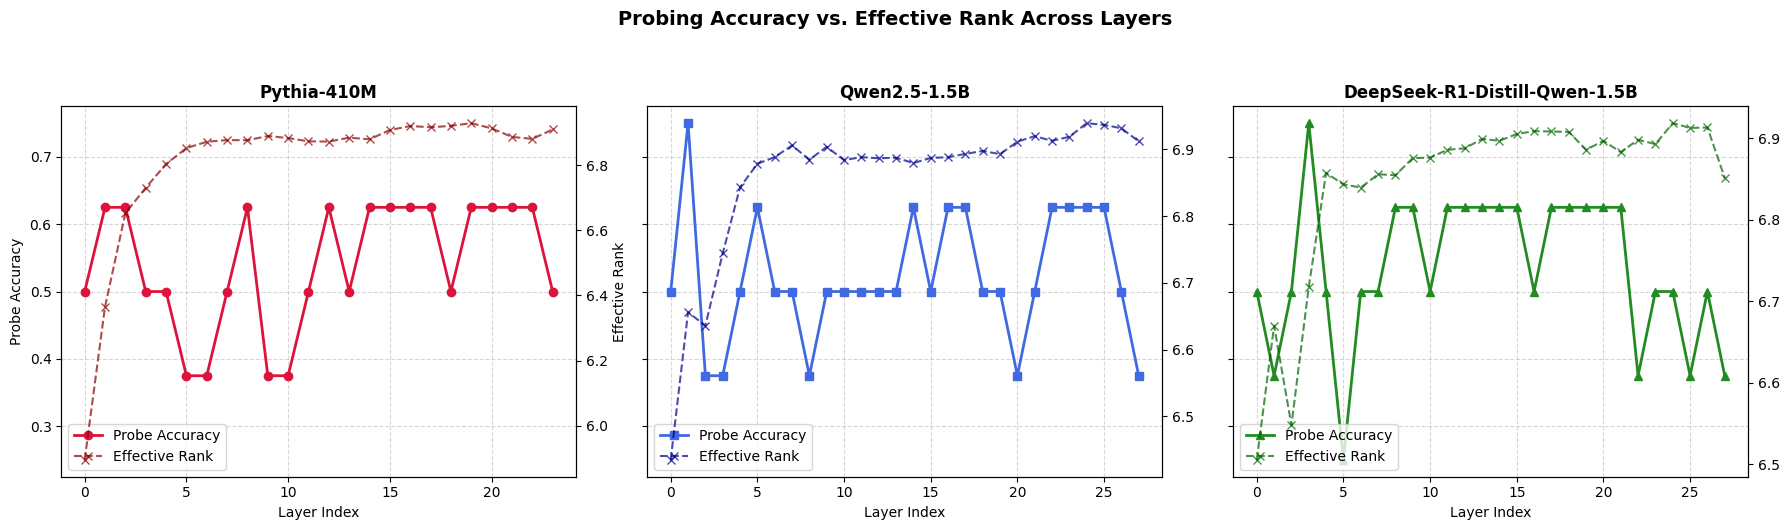

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# 1. Pythia-410M Comparison
ax1 = axes[0]
ax1_rank = ax1.twinx()
line1 = ax1.plot(range(len(probe_accuracies)), probe_accuracies, label="Probe Accuracy", marker='o', color='crimson', linewidth=2)
line2 = ax1_rank.plot(range(len(effective_ranks)), effective_ranks, label="Effective Rank", marker='x', color='darkred', linestyle='--', alpha=0.7)
ax1.set_title("Pythia-410M", fontsize=12, fontweight='bold')
ax1.set_xlabel("Layer Index")
ax1.set_ylabel("Probe Accuracy")
ax1_rank.set_ylabel("Effective Rank")
# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='lower left')
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Qwen2.5-1.5B Comparison
ax2 = axes[1]
ax2_rank = ax2.twinx()
line1_qw = ax2.plot(range(len(qwen_probe_accuracies)), qwen_probe_accuracies, label="Probe Accuracy", marker='s', color='royalblue', linewidth=2)
line2_qw = ax2_rank.plot(range(len(qwen_effective_ranks)), qwen_effective_ranks, label="Effective Rank", marker='x', color='darkblue', linestyle='--', alpha=0.7)
ax2.set_title("Qwen2.5-1.5B", fontsize=12, fontweight='bold')
ax2.set_xlabel("Layer Index")
lines_qw = line1_qw + line2_qw
labels_qw = [l.get_label() for l in lines_qw]
ax2.legend(lines_qw, labels_qw, loc='lower left')
ax2.grid(True, linestyle="--", alpha=0.5)

# 3. DeepSeek-R1-Distill-Qwen-1.5B Comparison
ax3 = axes[2]
ax3_rank = ax3.twinx()
line1_ds = ax3.plot(range(len(ds_probe_accuracies)), ds_probe_accuracies, label="Probe Accuracy", marker='^', color='forestgreen', linewidth=2)
line2_ds = ax3_rank.plot(range(len(ds_effective_ranks)), ds_effective_ranks, label="Effective Rank", marker='x', color='darkgreen', linestyle='--', alpha=0.7)
ax3.set_title("DeepSeek-R1-Distill-Qwen-1.5B", fontsize=12, fontweight='bold')
ax3.set_xlabel("Layer Index")
lines_ds = line1_ds + line2_ds
labels_ds = [l.get_label() for l in lines_ds]
ax3.legend(lines_ds, labels_ds, loc='lower left')
ax3.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Probing Accuracy vs. Effective Rank Across Layers", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

### Level 2: Scaled Evaluation with 100-Example Dataset

In [33]:
import numpy as np

# Let's programmatically construct a balanced dataset of 100 robust examples containing verified target words.
# Senses and POS variations will be labeled cleanly as (0 or 1).
level2_raw_dataset = [
    # --- "bank" (Senses: 0 = Financial, 1 = River/Physical) ---
    {"word": "bank", "text": "The local bank approved my mortgage application inside ten minutes.", "label": 0},
    {"word": "bank", "text": "I need to find an ATM near the commercial bank to withdraw cash.", "label": 0},
    {"word": "bank", "text": "She works as an investment analyst at a Swiss bank in Zurich.", "label": 0},
    {"word": "bank", "text": "The bank robbery was prevented by the quick reaction of the guards.", "label": 0},
    {"word": "bank", "text": "You can transfer the funds directly to my savings bank account.", "label": 0},
    {"word": "bank", "text": "He secured a low-interest personal loan from the local bank.", "label": 0},
    {"word": "bank", "text": "The central bank decided to raise interest rates to control inflation.", "label": 0},
    {"word": "bank", "text": "I opened a checking account at the neighborhood bank this morning.", "label": 0},
    {"word": "bank", "text": "They deposited their business earnings in a secure bank vault.", "label": 0},
    {"word": "bank", "text": "Online bank transactions are heavily encrypted to protect customer data.", "label": 0},
    {"word": "bank", "text": "The grassy bank of the winding river was perfect for a picnic.", "label": 1},
    {"word": "bank", "text": "We sat on the muddy bank and watched boats sail along the river.", "label": 1},
    {"word": "bank", "text": "The river bank collapsed after three days of torrential summer rain.", "label": 1},
    {"word": "bank", "text": "Beavers built their wooden lodge near the steep bank of the creek.", "label": 1},
    {"word": "bank", "text": "Flowers grew abundantly along the quiet canal bank in spring.", "label": 1},
    {"word": "bank", "text": "We walked down the steep bank to reach the cold water below.", "label": 1},
    {"word": "bank", "text": "He set up his fishing rod on the sandy bank of the lake.", "label": 1},
    {"word": "bank", "text": "The mossy bank of the stream was soft and comfortable to sit on.", "label": 1},
    {"word": "bank", "text": "Heavy clay forms the main foundation of this river bank structure.", "label": 1},
    {"word": "bank", "text": "A small pathway leads down the grassy bank toward the dock.", "label": 1},

    # --- "spring" (Senses: 0 = Season, 1 = Mechanical/Water source) ---
    {"word": "spring", "text": "I love when the warm weather of spring arrives after winter.", "label": 0},
    {"word": "spring", "text": "Beautiful cherry blossoms bloom across Japan every single spring season.", "label": 0},
    {"word": "spring", "text": "Our family plans to plant a vegetable garden early this spring.", "label": 0},
    {"word": "spring", "text": "The spring break vacation was a perfect time to relax and read.", "label": 0},
    {"word": "spring", "text": "Farmers prepare their tractors and fields during the busy spring months.", "label": 0},
    {"word": "spring", "text": "The weather in spring can be quite unpredictable with sudden rain.", "label": 0},
    {"word": "spring", "text": "Migrating birds return north during the early weeks of spring.", "label": 0},
    {"word": "spring", "text": "Green grass and bright flowers make spring my absolute favorite season.", "label": 0},
    {"word": "spring", "text": "We cleaned the entire house from top to bottom during spring break.", "label": 0},
    {"word": "spring", "text": "The forest comes alive with new animal life during the spring.", "label": 0},
    {"word": "spring", "text": "The metal spring inside the clock snapped and stopped the gears.", "label": 1},
    {"word": "spring", "text": "This old mattress is uncomfortable because a sharp spring is poking through.", "label": 1},
    {"word": "spring", "text": "The mechanical scale relies on a heavy iron spring for calibration.", "label": 1},
    {"word": "spring", "text": "We collected fresh drinking water directly from the natural mountain spring.", "label": 1},
    {"word": "spring", "text": "A tiny coil spring holds the battery firmly in place here.", "label": 1},
    {"word": "spring", "text": "The trampoline works because of many strong steel spring connectors.", "label": 1},
    {"word": "spring", "text": "The valve is kept closed tightly by a high-tension steel spring.", "label": 1},
    {"word": "spring", "text": "The hot spring was heated by volcanic activity deep underground.", "label": 1},
    {"word": "spring", "text": "You must compress the metal spring before inserting the latch mechanism.", "label": 1},
    {"word": "spring", "text": "Clean mineral water bubbles up continuously from the deep underground spring.", "label": 1},

    # --- "watch" (Senses: 0 = Noun/Device, 1 = Verb/Action) ---
    {"word": "watch", "text": "He wore an expensive gold watch that kept perfect time always.", "label": 0},
    {"word": "watch", "text": "The battery in my digital watch needs to be replaced soon.", "label": 0},
    {"word": "watch", "text": "She checked her pocket watch to see if she was late.", "label": 0},
    {"word": "watch", "text": "This vintage watch has a beautiful leather strap and brass dial.", "label": 0},
    {"word": "watch", "text": "A mechanical watch requires manual winding to keep running smoothly.", "label": 0},
    {"word": "watch", "text": "He received a silver watch as a retirement gift from work.", "label": 0},
    {"word": "watch", "text": "The glowing face of his sports watch was visible in the dark.", "label": 0},
    {"word": "watch", "text": "I lost my waterproof watch while swimming in the ocean yesterday.", "label": 0},
    {"word": "watch", "text": "Her diamond watch sparkled brightly under the strong gallery lights.", "label": 0},
    {"word": "watch", "text": "This smart watch tracks your daily steps and heart rate continuously.", "label": 0},
    {"word": "watch", "text": "We stood on the balcony to watch the colorful parade pass by.", "label": 1},
    {"word": "watch", "text": "I like to watch classical movies on rainy Sunday afternoons.", "label": 1},
    {"word": "watch", "text": "The children love to watch the penguins swim at the zoo.", "label": 1},
    {"word": "watch", "text": "You should watch your step on the icy stairs outside.", "label": 1},
    {"word": "watch", "text": "We gathered on the roof to watch the solar eclipse safely.", "label": 1},
    {"word": "watch", "text": "Please watch the soup so it does not boil over the pot.", "label": 1},
    {"word": "watch", "text": "I will watch the baby for an hour while you run errands.", "label": 1},
    {"word": "watch", "text": "They decided to watch the dramatic sunset from the beach cliff.", "label": 1},
    {"word": "watch", "text": "It is fascinating to watch spiders construct their complex webs.", "label": 1},
    {"word": "watch", "text": "Our family loves to watch the fireworks show on New Year's Eve.", "label": 1},

    # --- "record" (Senses: 0 = Noun, 1 = Verb) ---
    {"word": "record", "text": "The athletic champion set a brand new world record today.", "label": 0},
    {"word": "record", "text": "The school keeps a detailed attendance record for every student.", "label": 0},
    {"word": "record", "text": "She listened to her favorite vinyl record on the old turntable.", "label": 0},
    {"word": "record", "text": "The medical record contains all your past health history securely.", "label": 0},
    {"word": "record", "text": "This historic document is the oldest written record of the town.", "label": 0},
    {"word": "record", "text": "Our company has an outstanding safety record with zero accidents.", "label": 0},
    {"word": "record", "text": "He bought a rare jazz record at the music store downtown.", "label": 0},
    {"word": "record", "text": "The police officer checked the suspect's criminal record quickly.", "label": 0},
    {"word": "record", "text": "A public record of the transaction is available at City Hall.", "label": 0},
    {"word": "record", "text": "The thermometer reached a record high temperature of forty degrees.", "label": 0},
    {"word": "record", "text": "Please record the video lecture so we can study it later.", "label": 1},
    {"word": "record", "text": "The software allows you to record your own voice easily.", "label": 1},
    {"word": "record", "text": "The band went into the studio to record their debut album.", "label": 1},
    {"word": "record", "text": "I will record the meeting minutes for our administrative files.", "label": 1},
    {"word": "record", "text": "The security cameras record all activity around the building perimeter.", "label": 1},
    {"word": "record", "text": "Scientists record the seismic waves to monitor active volcano movement.", "label": 1},
    {"word": "record", "text": "Make sure to record your daily expenses in the spreadsheet file.", "label": 1},
    {"word": "record", "text": "They decided to record the live concert performance on tape.", "label": 1},
    {"word": "record", "text": "He used his smartphone to record the beautiful birdsong in forest.", "label": 1},
    {"word": "record", "text": "We must record every transaction to ensure financial transparency.", "label": 1},

    # --- "match" (Senses: 0 = Noun/Device, 1 = Verb/Compare) ---
    {"word": "match", "text": "He struck a wooden match against the box to light the candle.", "label": 0},
    {"word": "match", "text": "The football match was delayed due to a sudden thunderstorm.", "label": 0},
    {"word": "match", "text": "Keep the box of match sticks away from young children.", "label": 0},
    {"word": "match", "text": "The championship tennis match lasted for nearly four grueling hours.", "label": 0},
    {"word": "match", "text": "A single match was enough to start the campfire in the dark.", "label": 0},
    {"word": "match", "text": "I watched the thrilling chess match between two international grandmasters.", "label": 0},
    {"word": "match", "text": "She blew out the burning match after lighting the fireplace.", "label": 0},
    {"word": "match", "text": "The boxing match ended in a dramatic knockout during round three.", "label": 0},
    {"word": "match", "text": "The damp match failed to produce a flame when struck.", "label": 0},
    {"word": "match", "text": "Thousands of fans bought tickets for the local rugby match.", "label": 0},
    {"word": "match", "text": "These shoes do not match the color of your dress perfectly.", "label": 1},
    {"word": "match", "text": "We need to match the socks together after doing the laundry.", "label": 1},
    {"word": "match", "text": "The computer algorithm can match fingerprints in a few seconds.", "label": 1},
    {"word": "match", "text": "They try to match mentors with students who share similar interests.", "label": 1},
    {"word": "match", "text": "Our goal is to match the competitor's prices on all items.", "label": 1},
    {"word": "match", "text": "The paint store can match any color sample you bring in.", "label": 1},
    {"word": "match", "text": "The puzzle requires you to match the correct shapes together.", "label": 1},
    {"word": "match", "text": "Your actions should always match the promises you make publicly.", "label": 1},
    {"word": "match", "text": "It is difficult to match the performance of this advanced engine.", "label": 1},
    {"word": "match", "text": "The insurance company will match your retirement contributions up to five percent.", "label": 1}
]

print(f"Level 2 Dataset compiled successfully. Total examples: {len(level2_raw_dataset)}")

Level 2 Dataset compiled successfully. Total examples: 100


In [34]:
# Perform target token indexing for Level 2 across our target models
for item in level2_raw_dataset:
    # Pythia Tokenizer Localization
    item["target_idx"] = locate_target_token(item["text"], item["word"], tokenizer)

    # Qwen2.5 Tokenizer Localization
    item["gemma_target_idx"] = locate_target_token_gemma(item["text"], item["word"], gemma_tokenizer)

    # DeepSeek Tokenizer Localization
    item["deepseek_target_idx"] = locate_target_token_gemma(item["text"], item["word"], deepseek_tokenizer)

print("Verified all token locations for 100 sentences across Pythia, Qwen, and DeepSeek tokenizers.")

Verified all token locations for 100 sentences across Pythia, Qwen, and DeepSeek tokenizers.


In [35]:
# 1. Extract Activations for Level 2 across all three models
print("Extracting Pythia-410M level 2 activations...")
pythia_l2_cache = cache_activations(level2_raw_dataset, model, tokenizer)

print("Extracting Qwen2.5-1.5B level 2 activations...")
qwen_l2_cache = cache_gemma_activations(level2_raw_dataset, gemma_model, gemma_tokenizer)

print("Extracting DeepSeek-R1-Distill-Qwen-1.5B level 2 activations...")
ds_l2_cache = cache_deepseek_activations(level2_raw_dataset, deepseek_model, deepseek_tokenizer)

print("All Level 2 model activations successfully cached.")

Extracting Pythia-410M level 2 activations...
Extracting Qwen2.5-1.5B level 2 activations...
Extracting DeepSeek-R1-Distill-Qwen-1.5B level 2 activations...
All Level 2 model activations successfully cached.


In [36]:
# 2. Perform Multi-Model Level 2 evaluation (Probing & uncapped Effective Ranks)
l2_pythia_ranks, l2_pythia_accs = [], []
l2_qwen_ranks, l2_qwen_accs = [], []
l2_ds_ranks, l2_ds_accs = [], []

def run_l2_eval(cached_data, num_layers, key_prefix="x_next"):
    ranks = []
    accs = []
    words_group = [x["word"] for x in cached_data]
    y_labels = np.array([x["label"] for x in cached_data], dtype=np.int32)

    for l in range(num_layers):
        x_next = np.array([x["activations"][key_prefix][l] for x in cached_data], dtype=np.float32)

        # Rank calculation (now able to scale higher since N=100)
        centered = x_next - np.mean(x_next, axis=0)
        _, s, _ = np.linalg.svd(centered, full_matrices=False)
        s_norm = s / (np.sum(s) + 1e-9)
        entropy = -np.sum(s_norm * np.log(s_norm + 1e-9))
        ranks.append(np.exp(entropy))

        # Probe with cross-validation
        logo = LeaveOneGroupOut()
        scores = []
        for train_idx, test_idx in logo.split(x_next, y_labels, groups=words_group):
            probe = LogisticRegression(C=1.0, max_iter=1000)
            probe.fit(x_next[train_idx], y_labels[train_idx])
            scores.append(probe.score(x_next[test_idx], y_labels[test_idx]))
        accs.append(np.mean(scores))

    return ranks, accs

print("Evaluating Pythia L2 Metrics...")
l2_pythia_ranks, l2_pythia_accs = run_l2_eval(pythia_l2_cache, model.config.num_hidden_layers)

print("Evaluating Qwen L2 Metrics...")
l2_qwen_ranks, l2_qwen_accs = run_l2_eval(qwen_l2_cache, gemma_model.config.num_hidden_layers)

print("Evaluating DeepSeek L2 Metrics...")
l2_ds_ranks, l2_ds_accs = run_l2_eval(ds_l2_cache, deepseek_model.config.num_hidden_layers)

print("Level 2 Evaluation complete!")

Evaluating Pythia L2 Metrics...
Evaluating Qwen L2 Metrics...
Evaluating DeepSeek L2 Metrics...
Level 2 Evaluation complete!


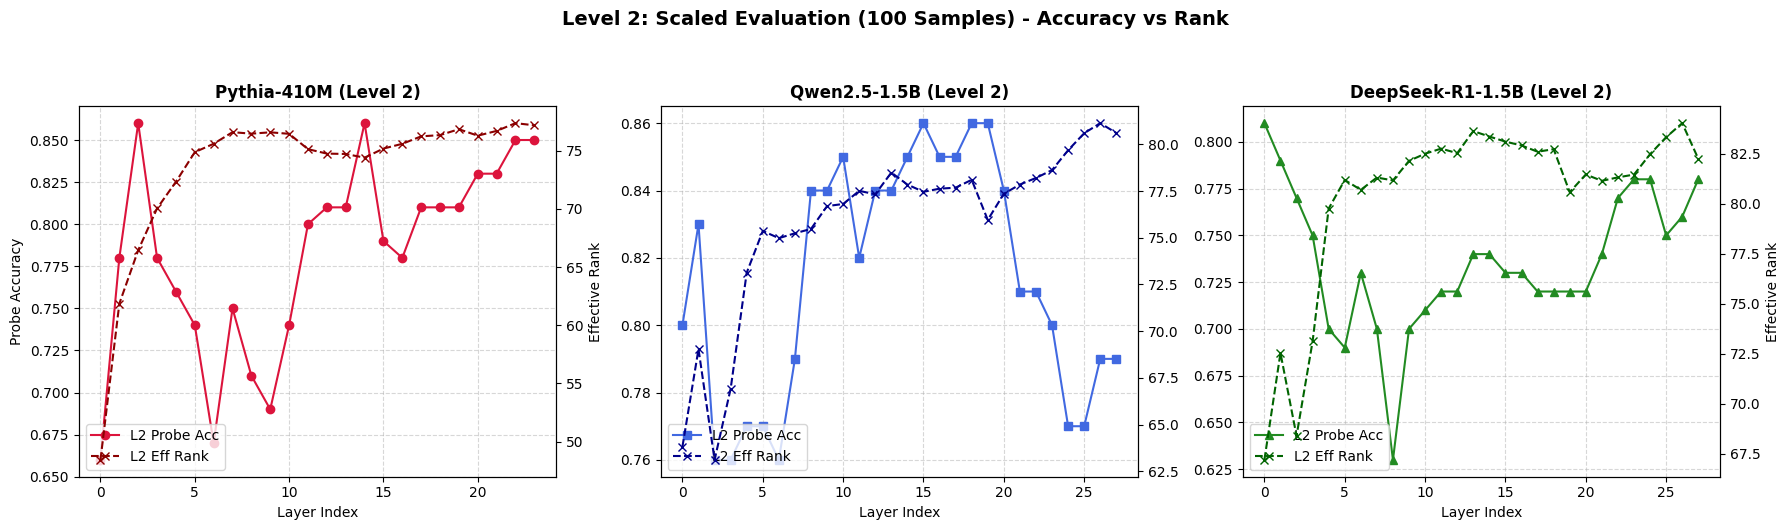

In [37]:
# 3. Plot Level 2 Comparison Results
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

# Pythia L2 Plot
ax1 = axes[0]
ax1_rank = ax1.twinx()
l1 = ax1.plot(range(len(l2_pythia_accs)), l2_pythia_accs, label="L2 Probe Acc", marker='o', color='crimson')
l2 = ax1_rank.plot(range(len(l2_pythia_ranks)), l2_pythia_ranks, label="L2 Eff Rank", marker='x', color='darkred', linestyle='--')
ax1.set_title("Pythia-410M (Level 2)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Layer Index")
ax1.set_ylabel("Probe Accuracy")
ax1_rank.set_ylabel("Effective Rank")
ax1.legend(l1+l2, [x.get_label() for x in l1+l2], loc='lower left')
ax1.grid(True, linestyle="--", alpha=0.5)

# Qwen L2 Plot
ax2 = axes[1]
ax2_rank = ax2.twinx()
l1_qw = ax2.plot(range(len(l2_qwen_accs)), l2_qwen_accs, label="L2 Probe Acc", marker='s', color='royalblue')
l2_qw = ax2_rank.plot(range(len(l2_qwen_ranks)), l2_qwen_ranks, label="L2 Eff Rank", marker='x', color='darkblue', linestyle='--')
ax2.set_title("Qwen2.5-1.5B (Level 2)", fontsize=12, fontweight='bold')
ax2.set_xlabel("Layer Index")
ax2.legend(l1_qw+l2_qw, [x.get_label() for x in l1_qw+l2_qw], loc='lower left')
ax2.grid(True, linestyle="--", alpha=0.5)

# DeepSeek L2 Plot
ax3 = axes[2]
ax3_rank = ax3.twinx()
l1_ds = ax3.plot(range(len(l2_ds_accs)), l2_ds_accs, label="L2 Probe Acc", marker='^', color='forestgreen')
l2_ds = ax3_rank.plot(range(len(l2_ds_ranks)), l2_ds_ranks, label="L2 Eff Rank", marker='x', color='darkgreen', linestyle='--')
ax3.set_title("DeepSeek-R1-1.5B (Level 2)", fontsize=12, fontweight='bold')
ax3.set_xlabel("Layer Index")
ax3_rank.set_ylabel("Effective Rank")
ax3.legend(l1_ds+l2_ds, [x.get_label() for x in l1_ds+l2_ds], loc='lower left')
ax3.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Level 2: Scaled Evaluation (100 Samples) - Accuracy vs Rank", fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()